In [ ]:
#Code with the topic: Regression Tree

#Objective

#The objective of this project is to develop a Regression Tree model
#to predict house prices based on area, number of bedrooms, and age.
#The model will be trained, evaluated, and used to predict the price
#of a new house.

#Technologies 

#Pandas 
#Matplotlib
#Scikit Learn
#Python
#Jupyter notebook
#Visual Studio Code

#Methodology

# 1. Load the house price dataset using Pandas.
# 2. Define the input features and target variable.
# 3. Split the dataset into training and testing sets.
# 4. Create and train a Decision Tree Regression model.
# 5. Generate predictions using the test data.
# 6. Evaluate the model using MSE, RMSE, and R² Score.
# 7. Predict the price of a new house using the trained model.
# 8. Visualize the regression tree and compare actual vs. predicted prices.

In [17]:
#We import the libraries

import pandas as pd 
import matplotlib.pyplot as plt 

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_squared_error, r2_score

In [18]:
#Load the dataset 

data = pd.read_csv("Regression_Tree.csv")

In [ ]:
#Visualization

data.info()

In [ ]:
data.describe()

In [ ]:
data.head()

In [19]:
#Define the features and target 

X = data[["Area", "Bedrooms", "Age"]]
y = data["Price"]

In [20]:
#Split the dataset into training and testing sets 

x_train,x_test,y_train,y_test = train_test_split(X,y, test_size=0.2, random_state=42)


print("\nTraining samples:", len(x_train))
print("Testing samples:", len(x_test))



Training samples: 11
Testing samples: 3


In [21]:
#Create the regression tree model

model = DecisionTreeRegressor(
        max_depth=4,
        random_state=42
    )


In [22]:
#Train the model 

model.fit(x_train,y_train)

print("\nModel training completed.")


Model training completed.


In [23]:
#Make predictions 

y_pred = model.predict(x_test)

print("\nActual prices:")
print(y_test.values)

print("\nPredicted prices:")
print(y_pred)



Actual prices:
[290000 170000 250000]

Predicted prices:
[230000. 180000. 230000.]


In [24]:
#Evaluate the model 

mse = mean_squared_error(y_test, y_pred)
rmse = mse ** 0.5
r2 = r2_score(y_test, y_pred)

print("\nModel Evaluation:")
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R² Score:", r2)




Model Evaluation:
Mean Squared Error: 1366666666.6666667
Root Mean Squared Error: 36968.45502136472
R² Score: 0.4508928571428571


In [25]:
#Predict the price of a new house

new_house = pd.DataFrame({
    "Area": [1550],
    "Bedrooms": [3],
    "Age": [5]
})

predicted_price = model.predict(new_house)

print("\nNew House:")
print(new_house)

print("\nPredicted House Price:")
print(f"${predicted_price[0]:,.2f}")


New House:
   Area  Bedrooms  Age
0  1550         3    5

Predicted House Price:
$320,000.00


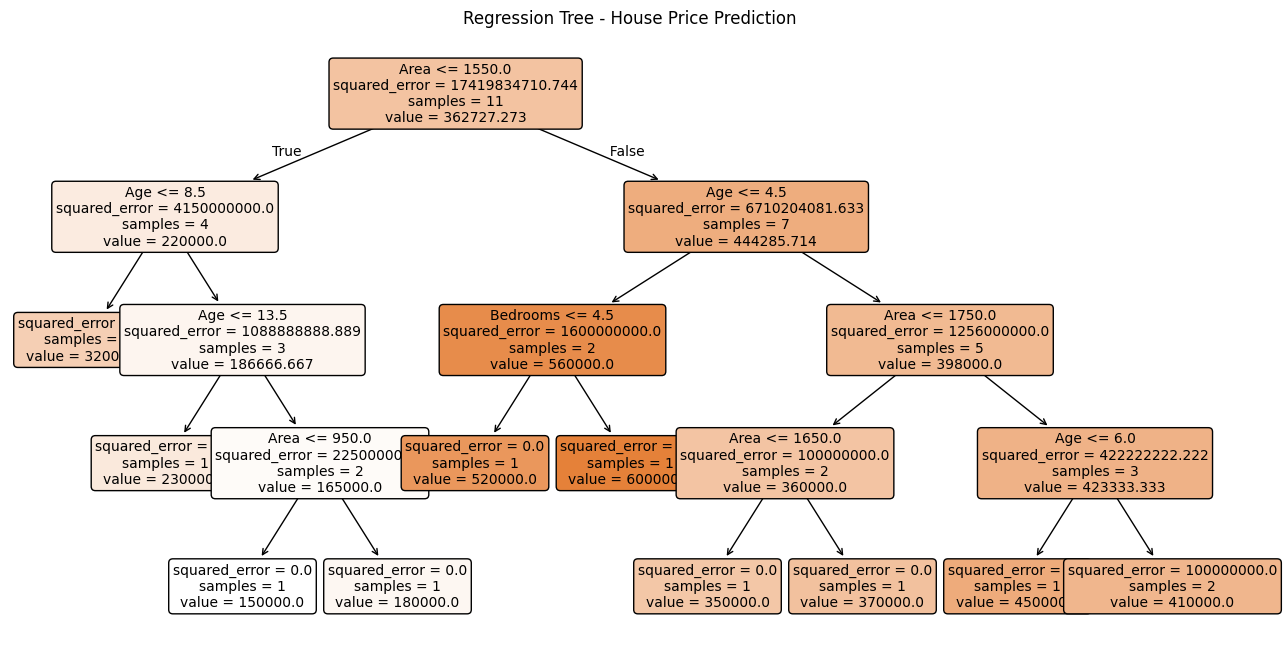

In [26]:
#Visualize the regression tree

plt.figure(figsize=(16, 8))

plot_tree(
    model,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Regression Tree - House Price Prediction")
plt.show()


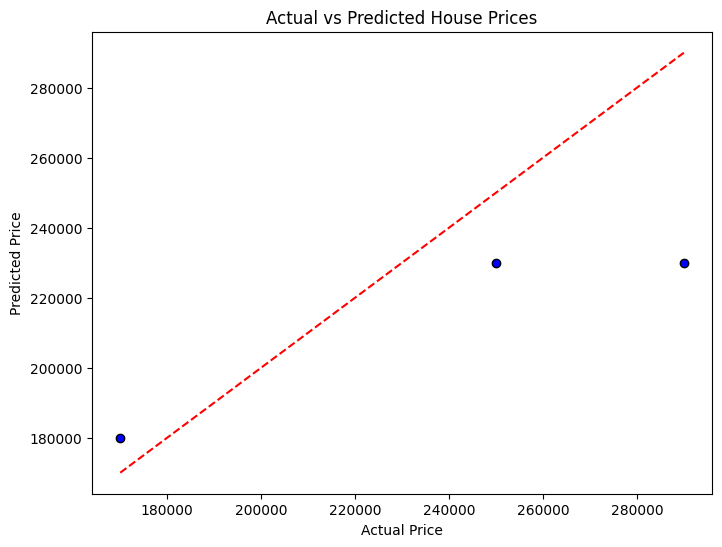

In [27]:
#Visualize actual vs predicted prices 

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    color="blue",
    edgecolor="black"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)

plt.show()